<a href="https://colab.research.google.com/github/ishitaa7880-bot/house-prices-eda/blob/main/house_price_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## EDA Project: Exploratory Analysis of House Prices

Title: Exploratory Data Analysis of the Ames Housing Dataset

Dataset: House Prices: Advanced Regression Techniques (Kaggle), file train.csv , about 1,460 rows and 81 columns.

Tools: Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy, Jupyter Notebook.

Objective: Use exploratory data analysis only (no machine learning) to understand which factors drive house sale prices, and to practise the full EDA workflow

In [3]:
#1. Import libraries and load dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("train.csv")

print(df.head())
print(df.shape)
print(df.info())

   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0   2008        WD   

In [4]:
#Step 2: Classify variables

# Numerical columns
numeric_cols = df.select_dtypes(include=np.number).columns

# Categorical columns
categorical_cols = df.select_dtypes(include='object').columns

print("Numerical Columns:")
print(numeric_cols)

print("Categorical Columns:")
print(categorical_cols)

print("Overall Quality:")
print(df['OverallQual'].dtype)


Numerical Columns:
Index(['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='object')
Categorical Columns:
Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinTyp

In [5]:
#Step 3: Descriptive statistics

# Basic statistics
print(df.describe())

# Mean, median and mode
columns = ['SalePrice', 'GrLivArea', 'LotArea']

for col in columns:
    print("\nColumn:", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())
    print("Range:", df[col].max() - df[col].min())
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())


                Id   MSSubClass  LotFrontage        LotArea  OverallQual  \
count  1460.000000  1460.000000  1201.000000    1460.000000  1460.000000   
mean    730.500000    56.897260    70.049958   10516.828082     6.099315   
std     421.610009    42.300571    24.284752    9981.264932     1.382997   
min       1.000000    20.000000    21.000000    1300.000000     1.000000   
25%     365.750000    20.000000    59.000000    7553.500000     5.000000   
50%     730.500000    50.000000    69.000000    9478.500000     6.000000   
75%    1095.250000    70.000000    80.000000   11601.500000     7.000000   
max    1460.000000   190.000000   313.000000  215245.000000    10.000000   

       OverallCond    YearBuilt  YearRemodAdd   MasVnrArea   BsmtFinSF1  ...  \
count  1460.000000  1460.000000   1460.000000  1452.000000  1460.000000  ...   
mean      5.575342  1971.267808   1984.865753   103.685262   443.639726  ...   
std       1.112799    30.202904     20.645407   181.066207   456.098091  ..

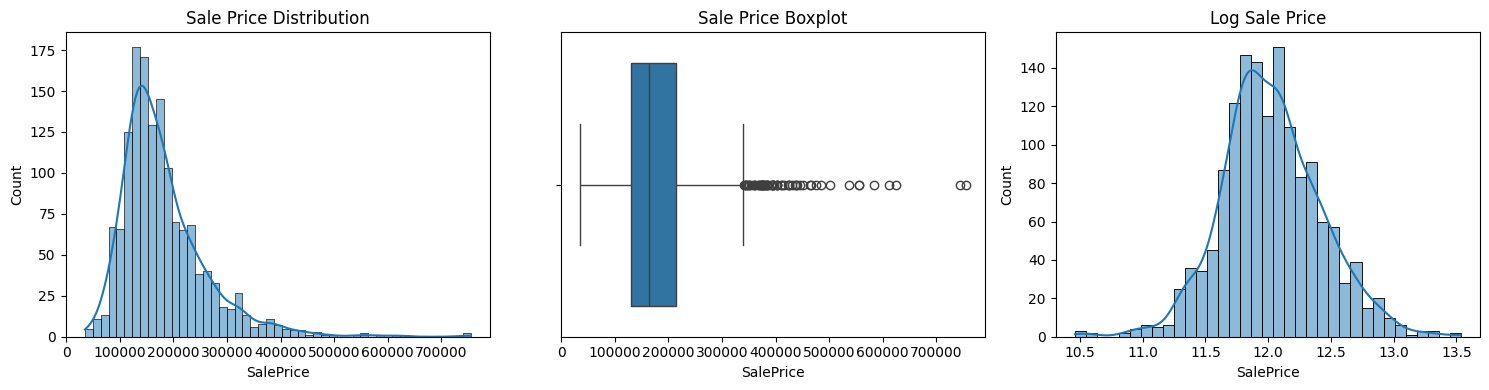

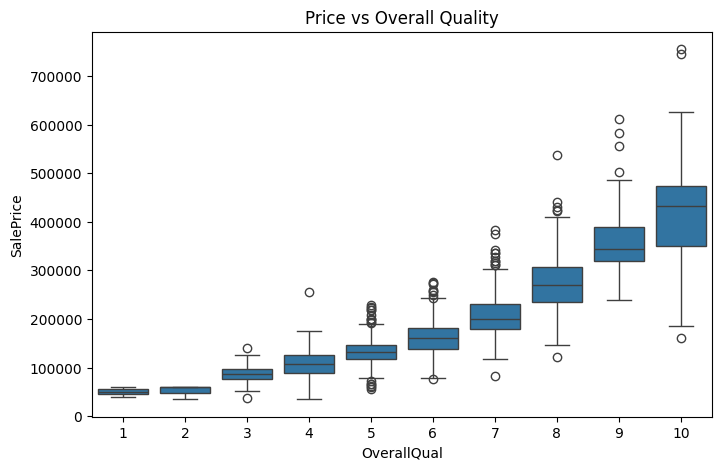

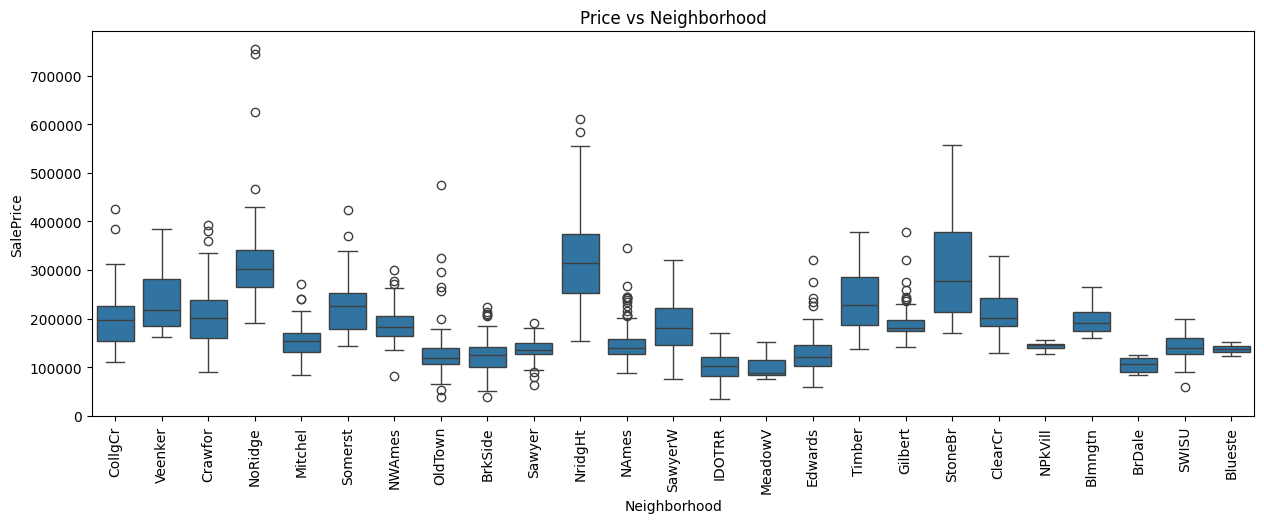

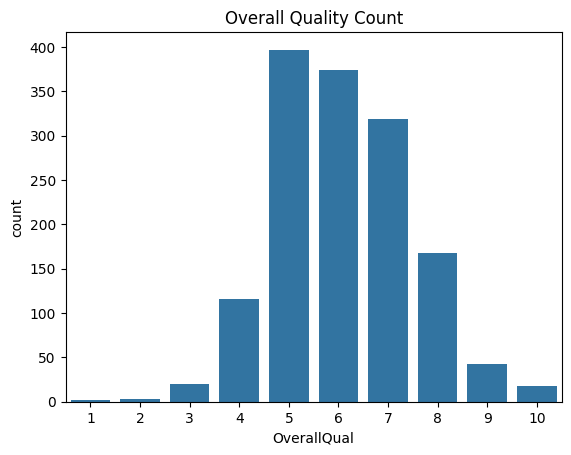

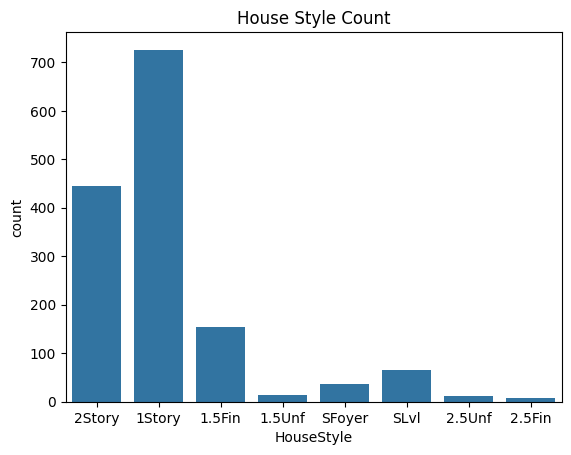

In [6]:
#Step 4: Data distribution and visualization

# Create 3 graphs
plt.figure(figsize=(15, 4))

# Histogram
plt.subplot(1, 3, 1)
sns.histplot(df['SalePrice'], kde=True)
plt.title("Sale Price Distribution")

# Boxplot
plt.subplot(1, 3, 2)
sns.boxplot(x=df['SalePrice'])
plt.title("Sale Price Boxplot")

# Log histogram
plt.subplot(1, 3, 3)
sns.histplot(np.log1p(df['SalePrice']), kde=True)
plt.title("Log Sale Price")

plt.tight_layout()
plt.show()

# Price according to quality
plt.figure(figsize=(8, 5))
sns.boxplot(x='OverallQual', y='SalePrice', data=df)
plt.title("Price vs Overall Quality")
plt.show()

# Price according to neighborhood
plt.figure(figsize=(15, 5))
sns.boxplot(x='Neighborhood', y='SalePrice', data=df)
plt.xticks(rotation=90)
plt.title("Price vs Neighborhood")
plt.show()

# Countplots
sns.countplot(x='OverallQual', data=df)
plt.title("Overall Quality Count")
plt.show()

sns.countplot(x='HouseStyle', data=df)
plt.title("House Style Count")
plt.show()


In [8]:
#Step 5: Correlation and covariance

# Correlation matrix
corr = df.select_dtypes(include=np.number).corr()

# Covariance matrix
cov = df.select_dtypes(include=np.number).cov()

print("Correlation:")
print(corr['SalePrice'].sort_values(ascending=False).head(10))

print("\nCovariance:")
print(cov['SalePrice'].sort_values(ascending=False).head(10))

# Top 3 correlated features
top3 = corr['SalePrice'].abs().sort_values(ascending=False).index[1:4]

for col in top3:
    print(col)
    print("Correlation:", corr.loc[col, 'SalePrice'])
    print("Covariance:", cov.loc[col, 'SalePrice'])


Correlation:
SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
Name: SalePrice, dtype: float64

Covariance:
SalePrice      6.311111e+09
LotArea        2.092111e+08
GrLivArea      2.958187e+07
TotalBsmtSF    2.138442e+07
1stFlrSF       1.860663e+07
BsmtFinSF1     1.400137e+07
2ndFlrSF       1.107415e+07
GarageArea     1.058910e+07
BsmtUnfSF      7.528864e+06
MasVnrArea     6.854858e+06
Name: SalePrice, dtype: float64
OverallQual
Correlation: 0.7909816005838053
Covariance: 86904.12583679946
GrLivArea
Correlation: 0.7086244776126515
Covariance: 29581866.743236575
GarageCars
Correlation: 0.6404091972583519
Covariance: 38020.18135897172


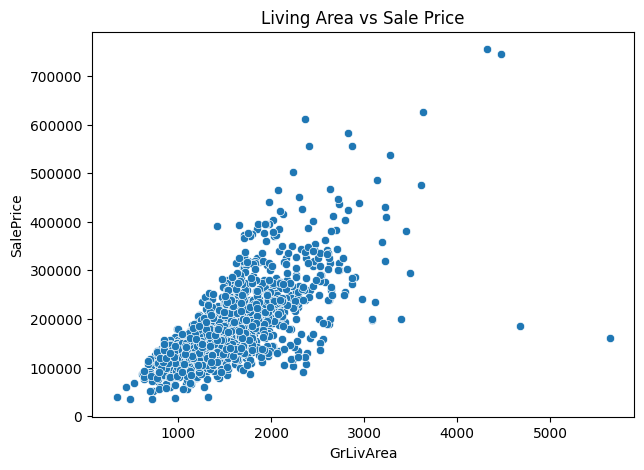

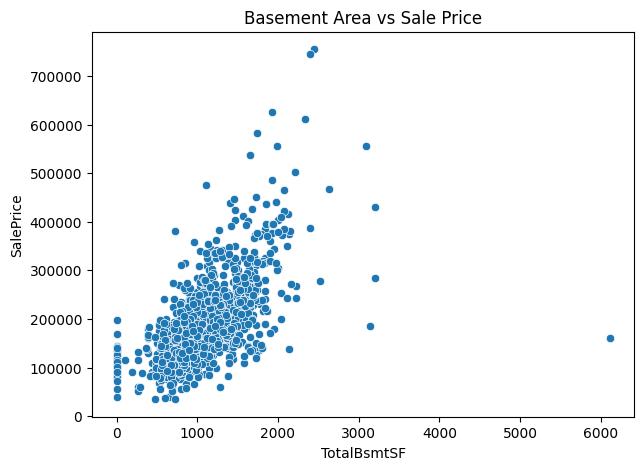

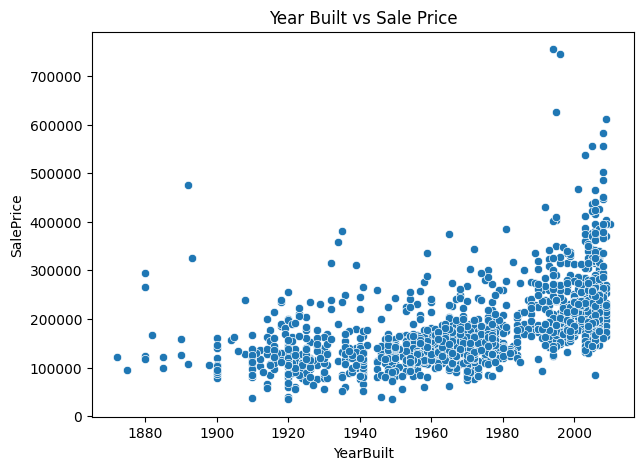

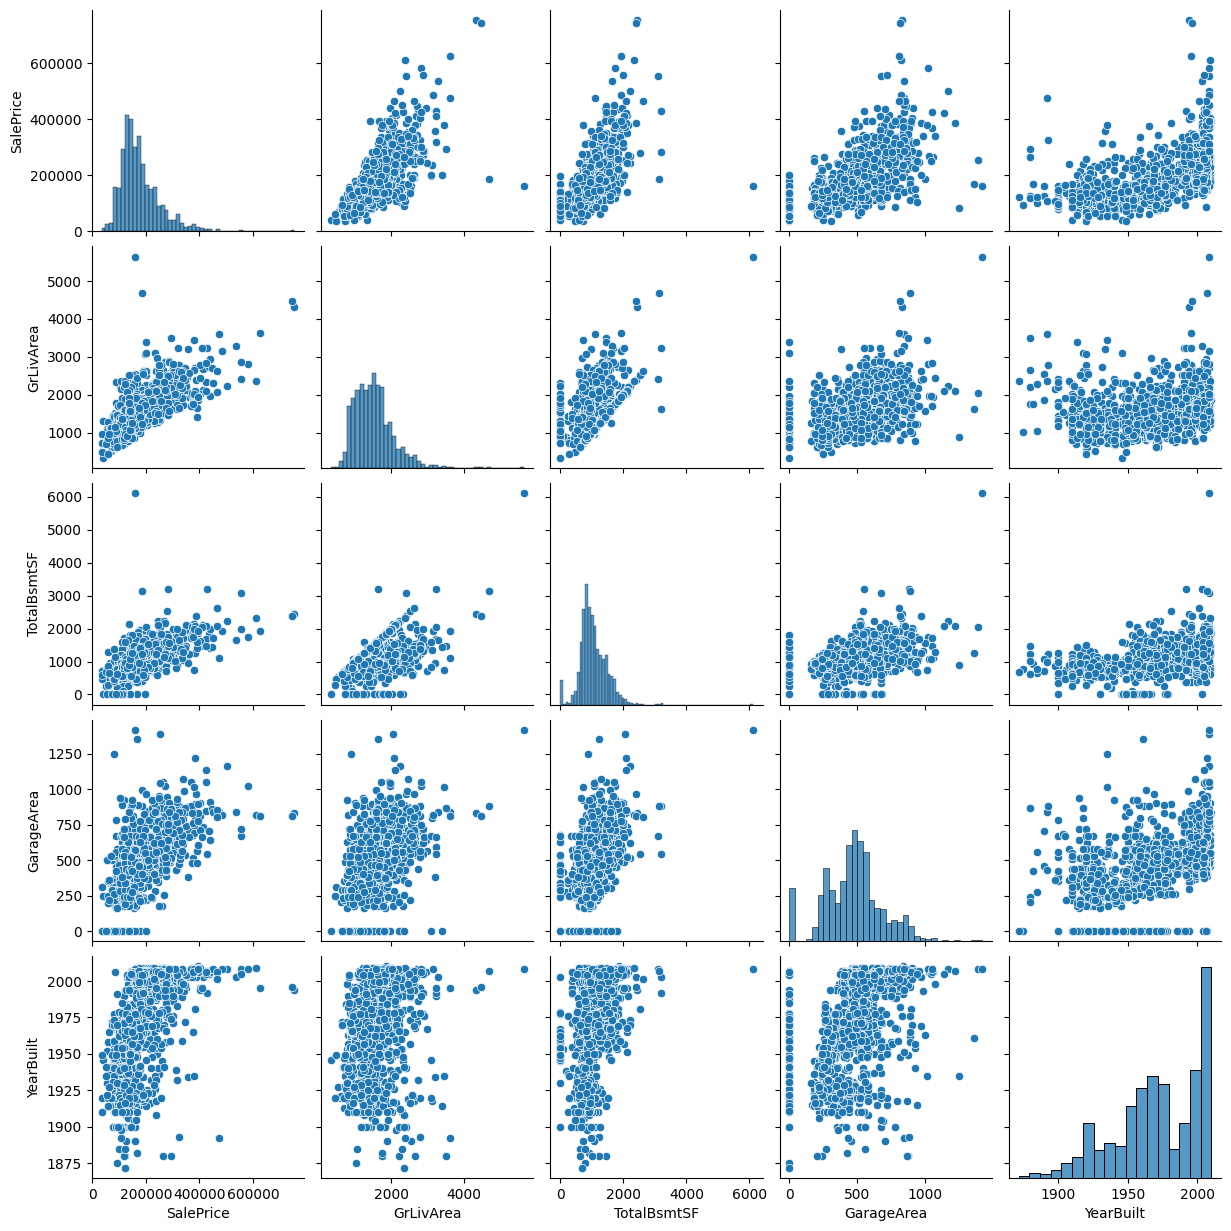

In [9]:
#Step 6: Scatter plots and pair plots

# Scatter plot 1
plt.figure(figsize=(7, 5))
sns.scatterplot(x='GrLivArea', y='SalePrice', data=df)
plt.title("Living Area vs Sale Price")
plt.show()

# Scatter plot 2
plt.figure(figsize=(7, 5))
sns.scatterplot(x='TotalBsmtSF', y='SalePrice', data=df)
plt.title("Basement Area vs Sale Price")
plt.show()

# Scatter plot 3
plt.figure(figsize=(7, 5))
sns.scatterplot(x='YearBuilt', y='SalePrice', data=df)
plt.title("Year Built vs Sale Price")
plt.show()

# Pair plot
selected = ['SalePrice', 'GrLivArea',
            'TotalBsmtSF', 'GarageArea', 'YearBuilt']

sns.pairplot(df[selected])
plt.show()


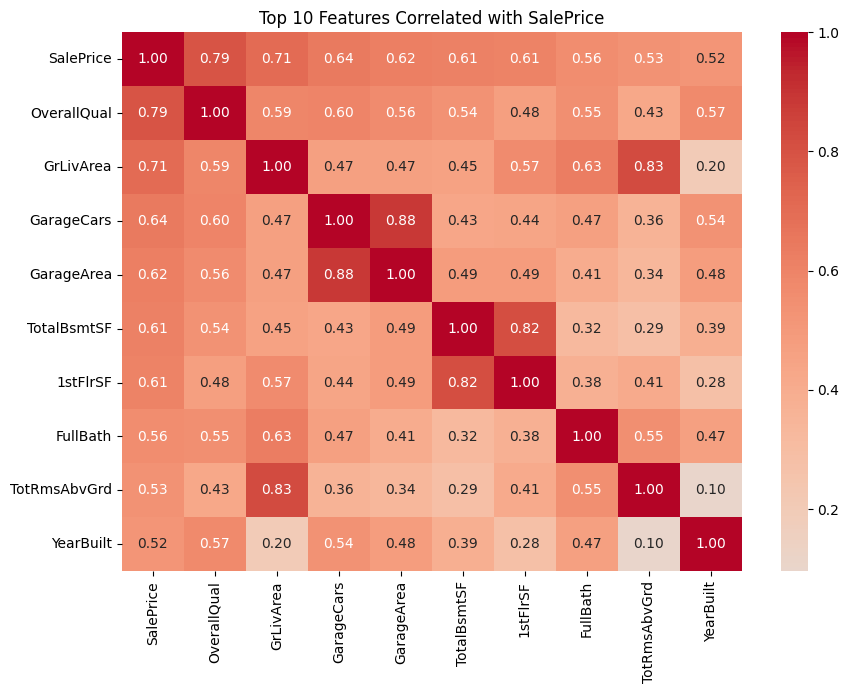

In [10]:
#Step 7: Correlation heatmap

# Find top 10 correlated columns
corr = df.select_dtypes(include=np.number).corr()

top10 = corr['SalePrice'].abs().sort_values(
    ascending=False
).head(10).index

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr.loc[top10, top10],
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title("Top 10 Features Correlated with SalePrice")
plt.show()



Column: GrLivArea
IQR Outliers: 31
Z-score Outliers: 16
Overlap: 16

Column: SalePrice
IQR Outliers: 61
Z-score Outliers: 22
Overlap: 22


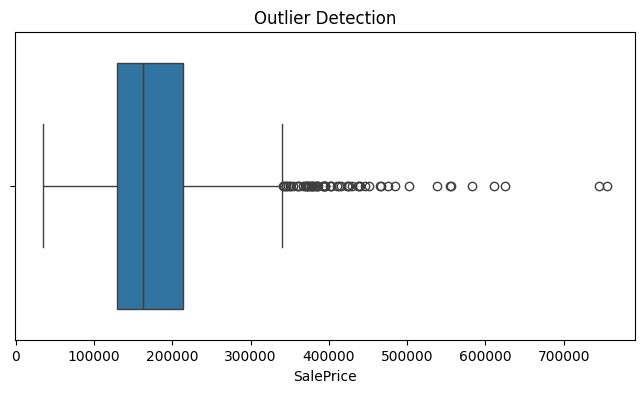

In [11]:
#Step 8: Outlier detection

# IQR method
def iqr_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return data[(data < lower) | (data > upper)]


# Z-score method
def zscore_outliers(data):
    z = (data - data.mean()) / data.std()

    return data[abs(z) > 3]


# Check outliers
for col in ['GrLivArea', 'SalePrice']:

    a = iqr_outliers(df[col])
    b = zscore_outliers(df[col])

    print("\nColumn:", col)
    print("IQR Outliers:", len(a))
    print("Z-score Outliers:", len(b))

    print("Overlap:", len(set(a.index) & set(b.index)))


# Boxplot
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['SalePrice'])
plt.title("Outlier Detection")
plt.show()


In [12]:
#Step 9: Data quality checks and cleaning

# Check duplicate rows
print("Duplicates:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

# Fill missing categorical values
columns = ['PoolQC', 'Alley', 'Fence',
           'FireplaceQu', 'GarageType']

for col in columns:
    df[col] = df[col].fillna('None')

# Fill LotFrontage with median
df['LotFrontage'] = df['LotFrontage'].fillna(
    df['LotFrontage'].median()
)

# Check missing values
print(df.isnull().sum().sort_values(ascending=False).head(20))

# Check incorrect values
print("Negative areas:")
print((df.select_dtypes(include=np.number) < 0).sum())


Duplicates: 0
MiscFeature     1406
MasVnrType       872
GarageCond        81
GarageYrBlt       81
GarageQual        81
GarageFinish      81
BsmtFinType2      38
BsmtExposure      38
BsmtFinType1      37
BsmtQual          37
BsmtCond          37
MasVnrArea         8
Electrical         1
MSSubClass         0
MSZoning           0
LotFrontage        0
Id                 0
HouseStyle         0
BldgType           0
Condition2         0
dtype: int64
Negative areas:
Id               0
MSSubClass       0
LotFrontage      0
LotArea          0
OverallQual      0
OverallCond      0
YearBuilt        0
YearRemodAdd     0
MasVnrArea       0
BsmtFinSF1       0
BsmtFinSF2       0
BsmtUnfSF        0
TotalBsmtSF      0
1stFlrSF         0
2ndFlrSF         0
LowQualFinSF     0
GrLivArea        0
BsmtFullBath     0
BsmtHalfBath     0
FullBath         0
HalfBath         0
BedroomAbvGr     0
KitchenAbvGr     0
TotRmsAbvGrd     0
Fireplaces       0
GarageYrBlt      0
GarageCars       0
GarageArea       0
WoodD

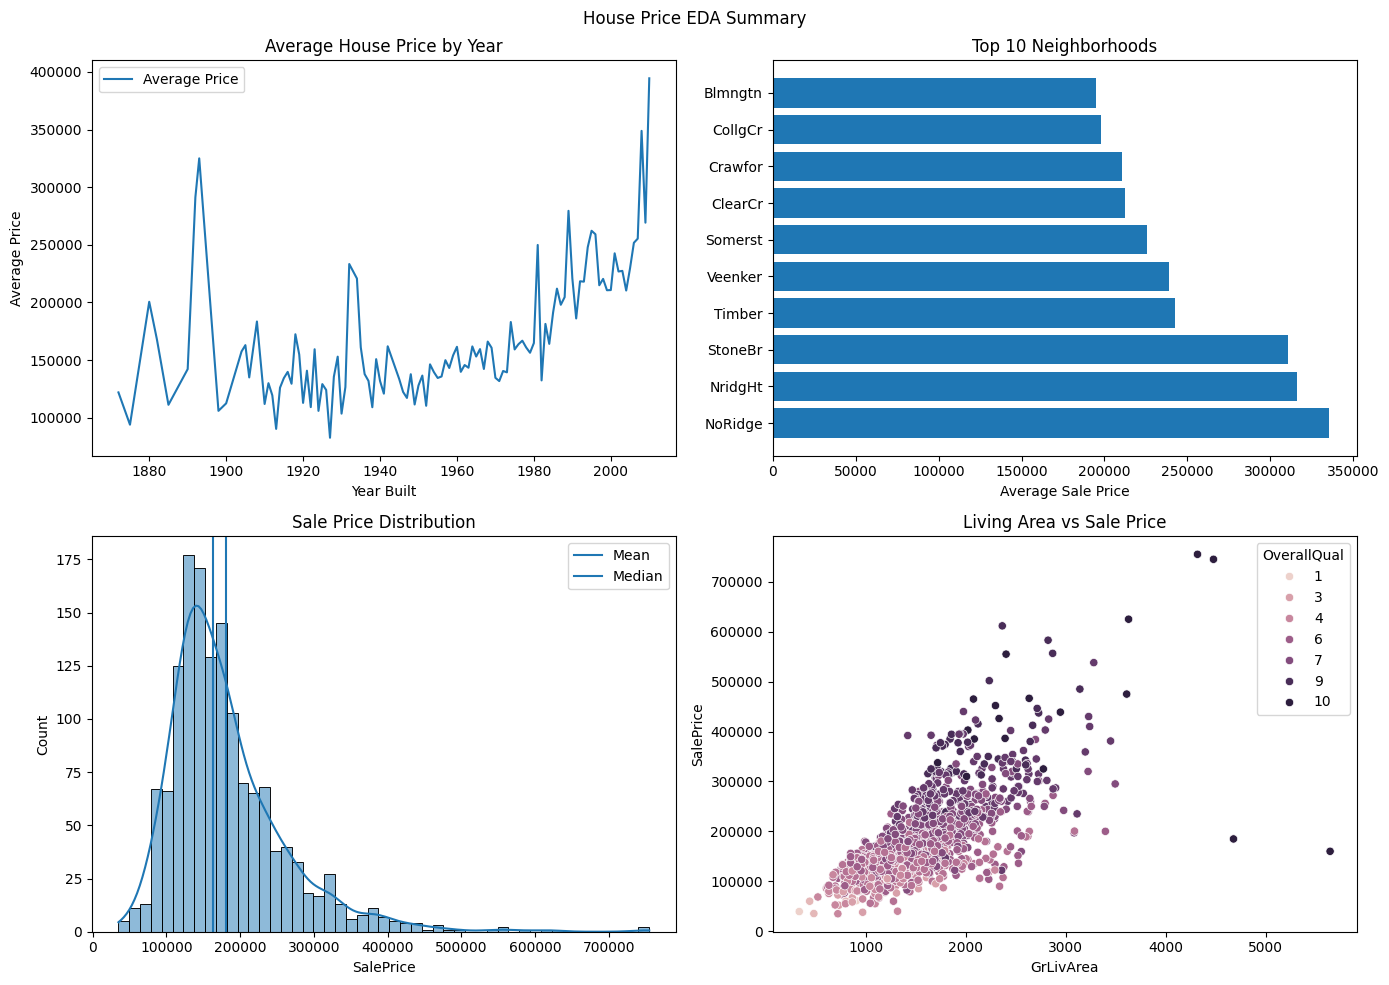

In [2]:
#Step 10: Final EDA dashboard

# Create dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Line plot: Average price by year
year_price = df.groupby('YearBuilt')['SalePrice'].mean()

axes[0, 0].plot(year_price.index, year_price.values)
axes[0, 0].set_title("Average House Price by Year")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average Price")
axes[0, 0].legend(["Average Price"])

# 2. Bar plot: Top 10 neighborhoods
neighborhood = df.groupby('Neighborhood')['SalePrice'].mean()
top_neighborhood = neighborhood.sort_values(
    ascending=False
).head(10)

axes[0, 1].barh(
    top_neighborhood.index,
    top_neighborhood.values
)
axes[0, 1].set_title("Top 10 Neighborhoods")
axes[0, 1].set_xlabel("Average Sale Price")

# 3. Histogram with mean and median
sns.histplot(df['SalePrice'], kde=True, ax=axes[1, 0])

mean_price = df['SalePrice'].mean()
median_price = df['SalePrice'].median()

axes[1, 0].axvline(mean_price, label="Mean")
axes[1, 0].axvline(median_price, label="Median")

axes[1, 0].set_title("Sale Price Distribution")
axes[1, 0].legend()

# 4. Scatter plot
sns.scatterplot(
    x='GrLivArea',
    y='SalePrice',
    hue='OverallQual',
    data=df,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Living Area vs Sale Price")

# Final dashboard
plt.suptitle("House Price EDA Summary")
plt.tight_layout()

# Save dashboard
plt.savefig("eda_dashboard.png")

plt.show()


## **Conclusion**

**Key Insights**

Sale Price Distribution: House prices are right-skewed, meaning most houses have moderate prices while a few houses have very high prices.

Important Features: Overall Quality and Living Area have a strong relationship with house prices.

Quality vs Price: Houses with higher overall quality generally have higher sale prices.

Neighborhood Analysis: Some neighborhoods have higher average house prices than others.

Outlier Detection: Some houses have unusually large living areas but comparatively low prices.

Missing Values: Some missing values represent the absence of a feature, such as a swimming pool or garage, rather than missing information.

**Limitations**

Limited Dataset: The analysis uses only the Ames Housing dataset, so the results may not apply to all housing markets.

Missing Data: Some columns contain missing values, which may affect the analysis.

Outliers: Unusual values can affect statistical calculations and visualizations.

No Machine Learning: This project focuses only on Exploratory Data Analysis and does not predict future house prices.

Correlation vs Causation: A strong correlation between two features does not prove that one feature causes a change in house prices.